# Modelo `log_pol`: Regresión Logística Polinomial (grado 2)
Entrenamiento, optimización (GridSearchCV), evaluación y exportación. Los datos y el split son idénticos a los de `../00_eda_y_comparacion.ipynb`
(80 % entrenamiento / 20 % prueba, estratificado, `random_state=42`).

**Por qué este modelo:** añade a la logística términos de **grado 2** (cuadrados e interacciones), lo que permite una **frontera de decisión no lineal** manteniendo un modelo
paramétrico. Aporta contraste frente a `svm` (otra forma de no linealidad) y a `reg_bin` (lineal). Riesgo: se pasa de 30 a **495 variables**,
con alto peligro de sobreajuste y multicolinealidad, por lo que la **regularización** (`C`, L1/L2) se ajusta con GridSearch.

In [1]:
# Librerías
import warnings
warnings.filterwarnings("ignore")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Datos y split 80/20

In [2]:
# Carga y limpieza (mismas decisiones que en el EDA): quitar 'id' y la columna vacía 'Unnamed: 32'
df = pd.read_csv("../../../data/data.csv")
df = df.drop(columns=["id"] + [c for c in df.columns if c.startswith("Unnamed")])

# Objetivo: M = 1 (clase positiva, maligno), B = 0
X = df.drop(columns="diagnosis")
y = df["diagnosis"].map({"B": 0, "M": 1})

# Split 80/20 estratificado (conserva la proporción de malignos)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"% maligno -> train: {100*y_train.mean():.1f} | test: {100*y_test.mean():.1f}")

Train: (455, 30) | Test: (114, 30)
% maligno -> train: 37.4 | test: 36.8


## 2. Pipeline y búsqueda de hiperparámetros
Todo el preprocesamiento va **dentro del `Pipeline`**, de modo que en cada fold de la validación cruzada el escalado se ajusta solo con los datos de entrenamiento de ese fold (sin *data leakage*).

Con 495 variables se explora un rango de `C` más fuerte en regularización (10⁻⁴ a 10¹).

**Métrica de selección:** `F1` de la clase maligna (equilibra precision y recall). También se registra `recall` y `roc_auc`;
la CV es **estratificada de 5 folds**.

In [3]:
pipe = Pipeline([
    ("scaler1", StandardScaler()),                     # escalar antes de elevar al cuadrado
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler2", StandardScaler()),                     # reescalar los términos polinómicos
    ("clf", LogisticRegression(solver="liblinear",
                               max_iter=5000, random_state=RANDOM_STATE)),
])

param_grid = {
    "clf__l1_ratio": [0, 1],                           # 0 = L2, 1 = L1
    "clf__C": np.logspace(-4, 1, 11),                  # rango más bajo: más regularización por las 495 variables
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid = GridSearchCV(
    pipe, param_grid,
    scoring={"f1": "f1", "recall": "recall", "roc_auc": "roc_auc"},
    refit="f1",            # el mejor modelo se elige por F1 y se reentrena con todo train
    cv=cv, n_jobs=-1, return_train_score=False,
)
grid.fit(X_train, y_train)

print("Mejores hiperparámetros:", grid.best_params_)
i = grid.best_index_
print("CV (media ± std) -> F1: %.4f ± %.4f | Recall: %.4f | AUC: %.4f" % (
    grid.cv_results_["mean_test_f1"][i], grid.cv_results_["std_test_f1"][i],
    grid.cv_results_["mean_test_recall"][i], grid.cv_results_["mean_test_roc_auc"][i]))

Mejores hiperparámetros: {'clf__C': np.float64(3.1622776601683795), 'clf__l1_ratio': 1}
CV (media ± std) -> F1: 0.9678 ± 0.0056 | Recall: 0.9706 | AUC: 0.9941


## 3. Evaluación en el conjunto de prueba (20 %)

In [4]:
best_pipe = grid.best_estimator_          # Pipeline completo ya reentrenado con todo el train
y_pred = best_pipe.predict(X_test)
y_prob = best_pipe.predict_proba(X_test)[:, 1]

metricas = {
    "accuracy":  accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred),
    "recall":    recall_score(y_test, y_pred),
    "f1":        f1_score(y_test, y_pred),
    "roc_auc":   roc_auc_score(y_test, y_prob),
}
print(pd.Series(metricas).round(4).to_string())
print()
print(classification_report(y_test, y_pred, target_names=["Benigno", "Maligno"]))

accuracy     0.9386
precision    0.9268
recall       0.9048
f1           0.9157
roc_auc      0.9914

              precision    recall  f1-score   support

     Benigno       0.95      0.96      0.95        72
     Maligno       0.93      0.90      0.92        42

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



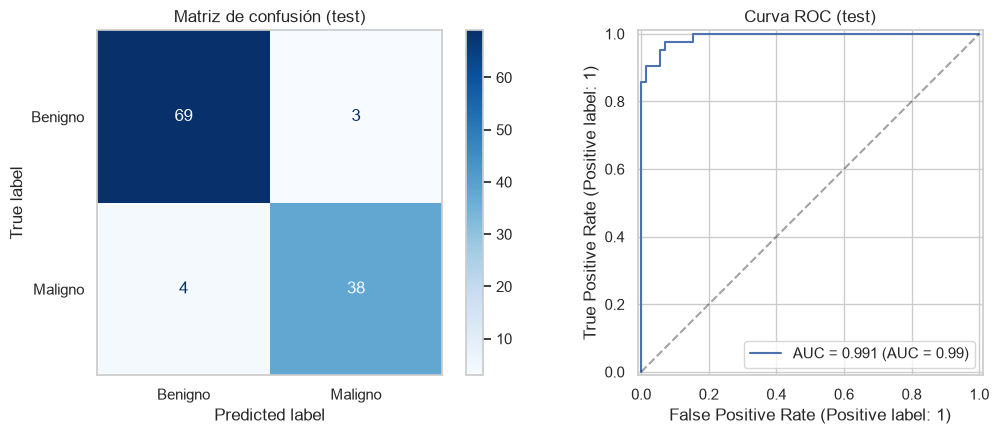

Falsos negativos (malignos no detectados): 4 | Falsos positivos: 3


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Benigno", "Maligno"],
                                        cmap="Blues", ax=axes[0])
axes[0].set_title("Matriz de confusión (test)")
axes[0].grid(False)

RocCurveDisplay.from_predictions(y_test, y_prob, name=f"AUC = {metricas['roc_auc']:.3f}", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", alpha=.4)
axes[1].set_title("Curva ROC (test)")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"Falsos negativos (malignos no detectados): {fn} | Falsos positivos: {fp}")

## 4. Interpretación del modelo

In [6]:
clf = best_pipe.named_steps["clf"]
n_total = clf.coef_.shape[1]
n_activos = int((clf.coef_[0] != 0).sum())
print(f"Variables polinómicas generadas: {n_total} | con coeficiente distinto de 0: {n_activos}")

nombres = best_pipe.named_steps["poly"].get_feature_names_out(X.columns)
coef = pd.Series(clf.coef_[0], index=nombres)
top = coef.reindex(coef.abs().sort_values(ascending=False).head(10).index)
print(top.round(3).to_string())

Variables polinómicas generadas: 495 | con coeficiente distinto de 0: 53
area_worst                  2.900
radius_se                   2.540
radius_se symmetry_worst   -2.404
concavity_mean              2.393
texture_worst               2.354
fractal_dimension_se       -2.030
area_se                     1.857
radius_worst                1.738
concavity_worst             1.561
compactness_se             -1.450


## 5. Exportación
Se guardan **dos artefactos**, ambos con `joblib`:
- `modelo/modelo.pkl` → solo el **estimador** entrenado (el paso final). Recibe datos **ya preprocesados**.
- `pipeline/pipeline.pkl` → el **Pipeline completo** (preprocesamiento + modelo). **Es el que debe usar la app**: recibe las 30 variables originales sin escalar.

In [7]:
from pathlib import Path
Path("modelo").mkdir(exist_ok=True); Path("pipeline").mkdir(exist_ok=True)

joblib.dump(best_pipe.named_steps["clf"], "modelo/modelo.pkl")
joblib.dump(best_pipe, "pipeline/pipeline.pkl")

# Métricas y configuración, para la comparación final en 00_eda_y_comparacion.ipynb
resumen = {
    "modelo": "log_pol",
    "mejores_hiperparametros": {k: (v.item() if hasattr(v, "item") else v) for k, v in grid.best_params_.items()},
    "cv_f1": float(grid.cv_results_["mean_test_f1"][grid.best_index_]),
    "cv_recall": float(grid.cv_results_["mean_test_recall"][grid.best_index_]),
    "test": {k: float(v) for k, v in metricas.items()},
    "falsos_negativos": int(fn), "falsos_positivos": int(fp),
    "features": list(X.columns),
}
with open("metricas.json", "w", encoding="utf-8") as f:
    json.dump(resumen, f, indent=2, ensure_ascii=False)
print("Artefactos guardados.")

Artefactos guardados.


### Verificación: recargar los `.pkl` y predecir

In [8]:
# El pipeline recargado debe dar exactamente las mismas predicciones que el original
pipe_cargado = joblib.load("pipeline/pipeline.pkl")
assert np.array_equal(pipe_cargado.predict(X_test), y_pred)
assert np.allclose(pipe_cargado.predict_proba(X_test)[:, 1], y_prob)

# El estimador suelto debe coincidir al alimentarlo con los datos ya transformados
modelo_cargado = joblib.load("modelo/modelo.pkl")
X_test_prep = best_pipe[:-1].transform(X_test)
assert np.array_equal(modelo_cargado.predict(X_test_prep), y_pred)

# Predicción de ejemplo con una fila cruda (como la recibiría la app)
fila = X_test.iloc[[0]]
p = pipe_cargado.predict_proba(fila)[0]
print(f"Real: {'Maligno' if y_test.iloc[0] else 'Benigno'} | "
      f"Predicho: {'Maligno' if p[1] > .5 else 'Benigno'} (P maligno = {p[1]:.3f})")
print("Verificación OK: los .pkl reproducen las predicciones.")

Real: Benigno | Predicho: Benigno (P maligno = 0.000)
Verificación OK: los .pkl reproducen las predicciones.
